In [1]:
import pandas as pd
import numpy as np
import os
import math
import seaborn as sns
import matplotlib.pyplot as plt
import librosa
import copy
import librosa.display
from IPython.display import Audio
import csv
import warnings
warnings.filterwarnings('ignore')
import pywt
import librosa
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
import torchvision.models as models
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

In [2]:
class Resnet18_RNN_Model(nn.Module):
    def __init__(self, num_classes):
        super(Resnet18_RNN_Model, self).__init__()
        # CNN feature extractor
        self.cnn = models.resnet18(pretrained=True)
        self.cnn.fc = nn.Identity()
        self.cnn.conv1 = nn.Conv2d(1, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
        
        # RNN sequence model
        self.rnn = nn.LSTM(input_size=512, hidden_size=256, num_layers=1, batch_first=True)
        
        # Classification head
        self.fc = nn.Linear(128, num_classes)
        
    def forward(self, x):
        # Add a channel dimension to the input data
        x = x.unsqueeze(1)

        # CNN feature extraction
        features = self.cnn(x)

        # Reshape features for RNN input (batch_size, sequence_length, num_features)
        features = features.unsqueeze(1)

        # RNN sequence modeling
        rnn_output, _ = self.rnn(features)

        # Classification
        output = self.fc(rnn_output[:, -1, :])

        return output


In [3]:
# Define your custom dataset
class SpeechDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


In [4]:
# Function to calculate evaluation metrics
def calculate_metrics(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    
    # Convert from one-hot encoding to class labels if needed
    if len(y_true.shape) > 1:
        y_true = np.argmax(y_true, axis=1)
    if len(y_pred.shape) > 1:
        y_pred = np.argmax(y_pred, axis=1)
    
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average='weighted')
    recall = recall_score(y_true, y_pred, average='weighted')
    f1 = f1_score(y_true, y_pred, average='weighted')
    return accuracy, precision, recall, f1


# Validation function
def validate(model, val_loader, criterion, device):
    model.eval()
    val_loss = 0.0
    y_true = []
    y_pred = []
    
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs = inputs.to(device)
            labels = torch.argmax(labels, axis=1).to(device)  # Convert one-hot to class labels
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            val_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs, 1)
            y_true.extend(labels.cpu().numpy())
            y_pred.extend(predicted.cpu().numpy())

    val_loss /= len(val_loader.dataset)
    accuracy, precision, recall, f1 = calculate_metrics(y_true, y_pred)
    
    return val_loss, accuracy, precision, recall, f1


In [5]:
def plot_graphs(epochs_path,
                num_epochs,
                train_losses,
                val_losses,
                train_accuracies,
                val_accuracies,
                train_precisions,
                val_precisions,
                train_recalls,
                val_recalls,
                train_f1s,
                val_f1s):
    
    
    # Plotting the metrics
    epochs = list(range(num_epochs))

    plt.figure(figsize=(10, 6))
    
    plt.plot(epochs, train_losses, label='Training Loss')
    plt.plot(epochs, val_losses, label='Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.title('Training and Validation Loss')
    plt.legend()
    plt.savefig(os.path.join(epochs_path, 'loss_plot.png'))
    plt.show()
    plt.close()

    plt.figure(figsize=(10, 6))
    
    plt.plot(epochs, train_accuracies, label='Training Accuracy')
    plt.plot(epochs, val_accuracies, label='Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.title('Training and Validation Accuracy')
    plt.legend()
    plt.savefig(os.path.join(epochs_path, 'accuracy_plot.png'))
    plt.show()
    plt.close()


    plt.figure(figsize=(10, 6))

    plt.plot(epochs, train_precisions, label='Training Precision')
    plt.plot(epochs, val_precisions, label='Validation Precision')
    plt.xlabel('Epochs')
    plt.ylabel('Precision')
    plt.title('Training and Validation Precision')
    plt.legend()
    plt.savefig(os.path.join(epochs_path, 'precision_plot.png'))
    plt.show()
    plt.close()
    
    plt.figure(figsize=(10, 6))

    plt.plot(epochs, train_recalls, label='Training Recall')
    plt.plot(epochs, val_recalls, label='Validation Recall')
    plt.xlabel('Epochs')
    plt.ylabel('Recall')
    plt.title('Training and Validation Recall')
    plt.legend()
    plt.savefig(os.path.join(epochs_path, 'recall_plot.png'))
    plt.show()
    plt.close()

    plt.figure(figsize=(10, 6))
    
    plt.plot(epochs, train_f1s, label='Training F1-score')
    plt.plot(epochs, val_f1s, label='Validation F1-score')
    plt.xlabel('Epochs')
    plt.ylabel('F1-score')
    plt.title('Training and Validation F1-score')
    plt.legend()
    plt.savefig(os.path.join(epochs_path, 'f1Score_plot.png'))
    plt.show()
    plt.close()

    return "Model Training and Evaluation Successfully completed"

In [6]:
def generate_confusion_matrix(model, test_loader, device):
    model.eval()
    y_true = []
    y_pred = []

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs = inputs.to(device)
            labels = torch.argmax(labels, axis=1).to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)
            y_true.extend(labels.cpu().numpy())
            y_pred.extend(predicted.cpu().numpy())
            
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average='weighted')
    recall = recall_score(y_true, y_pred, average='weighted')
    f1 = f1_score(y_true, y_pred, average='weighted')        
    print(f"\nAccuracy : {accuracy}\nPrecision : {precision}\nRecall : {recall}\nF1-Score : {f1}")

    conf_matrix = confusion_matrix(y_true, y_pred)
    return conf_matrix, y_true, y_pred

def plot_confusion_matrices(conf_matrix, normalized_conf_matrix, class_labels, epochs_path):
    plt.figure(figsize=(10, 6))
    sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', annot_kws={"fontsize": 12})  
    plt.xlabel('Predicted labels')
    plt.ylabel('True labels')
    plt.title('Confusion Matrix')
    plt.xticks(ticks=np.arange(len(class_labels)), labels=class_labels)
    plt.yticks(ticks=np.arange(len(class_labels)), labels=class_labels)
    plt.savefig(os.path.join(epochs_path, 'Confusion Matrix.png'))
    plt.show()
    
    plt.figure(figsize=(10, 6))
    sns.heatmap(normalized_conf_matrix, annot=True, cmap='Blues', annot_kws={"fontsize": 12})
    plt.xlabel('Predicted labels')
    plt.ylabel('True labels')
    plt.title('Normalized Confusion Matrix')
    plt.xticks(ticks=np.arange(len(class_labels)), labels=class_labels)
    plt.yticks(ticks=np.arange(len(class_labels)), labels=class_labels)
    plt.savefig(os.path.join(epochs_path, 'Normalized Confusion Matrix.png'))
    plt.show()


In [7]:
def train_model():
    
    global dwt_level,model,mfcc
    
    dataset=input("Enter dataset name:\ntess, savee, crema, ravdess\n ")
    dwt_level = int(input("Enter dwt level:  "))
    mfcc=int(input("Enter Number of MFCC coefficients : "))
    if dataset=="tess":
        csv_file=r"C:\Users\Tharunraj_S\Desktop\Major project\Dataset\tess_dataset.csv"
    
    elif dataset=="savee":
        csv_file=r"C:\Users\Tharunraj_S\Desktop\Major project\Dataset\savee_dataset.csv"
    
    elif dataset=="crema":
        csv_file=r"C:\Users\Tharunraj_S\Desktop\Major project\Dataset\crema_dataset.csv"
    
    elif dataset=="ravdess":
        csv_file=r"C:\Users\Tharunraj_S\Desktop\Major project\Dataset\ravdess_dataset.csv"
    
    
    df = pd.read_csv(csv_file)
    X_mfcc = df['File_Path'].apply(lambda x: extract_features(x,dwt_level))
    
    X = [x for x in X_mfcc]
    X = np.array(X)
    X = X.reshape(-1, 1, mfcc*(dwt_level+1))
    
    class_labels = df['Emotion_Label'].unique().tolist()
    
    from sklearn.preprocessing import OneHotEncoder
    enc = OneHotEncoder()
    y = enc.fit_transform(df[['Emotion_Label']])
    y = y.toarray()
    
    train_loader, val_loader = Loader(X, y) 
      
    # Determine input size based on wavelet level
    input_size = mfcc*(dwt_level+1)
    hidden_size = 256
    num_layers=3 
    nhead=8  
        
    print(f"Input size for wavelet level {dwt_level} = {input_size}")
    # Initialize model

    model = Resnet18_RNN_Model(num_classes=num_classes)
    
    model_path=model.__class__.__name__
    if not os.path.exists( model_path):
        os.makedirs( model_path)
        
    # Loss and optimizer
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    # Reset model parameters
    model.apply(reset_parameters)
    
    # Reset optimizer state
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    # Initialize variables to store best validation metrics and corresponding model state
    best_val_loss = float('inf')
    best_model_state = None
    no_improvement_count = 0
    
    # Training loop
    
    train_losses = []
    val_losses = []
    train_accuracies = []
    val_accuracies = []
    train_precisions = []
    val_precisions = []
    train_recalls = []
    val_recalls = []
    train_f1s = []
    val_f1s = []
    
    print("Training with DWT level:", dwt_level)
    print(
          f'Hidden Size : {hidden_size}\n' 
          f'Model Name: {model.__class__.__name__}\n' 
          f'\nX Shape : {X.shape}'
          f'\nY Shape : {y.shape}\n')
    num_epochs =int(input("Enter no. of epochs "))
    dataset_path = dataset
    dataset_dir = os.path.join(model_path,dataset_path)
    if not os.path.exists(dataset_dir):
        os.makedirs(dataset_dir)
        
    mfcc_path="N_MFCC"+str(mfcc)
    mfcc_dir=os.path.join(dataset_dir,mfcc_path)
    
    dwt_level_path = "level "+str(dwt_level)+" wavelet"
    dwt_level_dir = os.path.join(mfcc_dir,dwt_level_path)
    if not os.path.exists(dwt_level_dir):
        os.makedirs(dwt_level_dir)
    
    # Create a directory with the name as the number of epochs
    epochs_dir = str(num_epochs)+" Epochs"
    epochs_path = os.path.join(dwt_level_dir,epochs_dir)
    if not os.path.exists(epochs_path):
        os.makedirs(epochs_path)
        
    with open(os.path.join(epochs_path,'metrics.csv'), mode='w', newline='') as file:
        writer = csv.writer(file)
        writer.writerow(['Epoch', 'Training Loss', 'Training Accuracy','Training Precision', 'Training Recall', 'Training F1-Score'
                         , 'Validation Loss', 'Validation Accuracy','Validation Precision', 'Validation Recall', 'Validation F1-Score'])

        for epoch in range(num_epochs):
            model.train()
            running_loss = 0.0

            for inputs, labels in train_loader:
                inputs = inputs.to(device)
                labels = labels.to(device)
                optimizer.zero_grad()
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                loss.backward()
                optimizer.step()
                running_loss += loss.item() * inputs.size(0)

            # Calculate training loss
            train_loss = running_loss / len(train_loader.dataset)
            train_losses.append(train_loss)

            # Calculate training metrics
            y_true_train = []
            y_pred_train = []
            with torch.no_grad():
                for inputs, labels in train_loader:
                    inputs = inputs.to(device)
                    labels = labels.to(device)
                    outputs = model(inputs)
                    _, predicted = torch.max(outputs, 1)
                    y_true_train.extend(labels.cpu().numpy())
                    y_pred_train.extend(predicted.cpu().numpy())

            train_accuracy, train_precision, train_recall, train_f1 = calculate_metrics(y_true_train, y_pred_train)
            train_accuracies.append(train_accuracy)
            train_precisions.append(train_precision)
            train_recalls.append(train_recall)
            train_f1s.append(train_f1)

            # Validate the model
            val_loss, val_accuracy, val_precision, val_recall, val_f1 = validate(model, val_loader, criterion, device)
            val_losses.append(val_loss)
            val_accuracies.append(val_accuracy)
            val_precisions.append(val_precision)
            val_recalls.append(val_recall)
            val_f1s.append(val_f1)

            # Write metrics to CSV
            writer.writerow([epoch+1, train_loss, train_accuracy, train_precision, train_recall, train_f1,
                             val_loss, val_accuracy, val_precision, val_recall, val_f1])


            print(f'Epoch [{epoch+1}/{num_epochs}],\n'
                  f'Training Loss: {train_loss:.4f}, Training Accuracy: {train_accuracy:.4f}, '
                  f'Training Precision:{train_precision:.4f},Training Recall:{train_recall:.4f},Training F1-Score:{train_f1:.4f}\n'
                  f'Validation Loss: {val_loss:.4f}, Validation Accuracy: {val_accuracy:.4f}, '
                  f'Validation Precision:{val_precision:.4f},Validation Recall:{val_recall:.4f},Validation F1-Score:{val_f1:.4f}'
                  )
            # Save the model
            torch.save(model.state_dict(), os.path.join(epochs_path, 'LSTM_model_(last).pth'))

            # Save the model if it has the best validation loss so far
            if val_loss < best_val_loss:
                best_val_loss = val_loss
                best_model_state = model.state_dict()
                torch.save(model.state_dict(), os.path.join(epochs_path, 'LSTM_model_(best).pth'))
                no_improvement_count = 0
            else:
                no_improvement_count += 1
                
    
    # Load the best model state
    model.load_state_dict(best_model_state)
    conf_matrix, _, _ = generate_confusion_matrix(model, val_loader, device)
    normalized_conf_matrix = conf_matrix.astype('float') / conf_matrix.sum(axis=1)[:, np.newaxis]
    plot_confusion_matrices(conf_matrix, normalized_conf_matrix, class_labels, epochs_path)
     
    return plot_graphs(epochs_path,num_epochs,train_losses,val_losses,train_accuracies,val_accuracies,train_precisions,val_precisions,train_recalls,val_recalls,train_f1s,val_f1s)


def reset_parameters(layer):
    if isinstance(layer, nn.Conv1d) or isinstance(layer, nn.Linear):
        nn.init.xavier_uniform_(layer.weight)
        nn.init.zeros_(layer.bias)

In [8]:
def Loader(X,y):
    
    global num_classes

    
    num_classes = y.shape[1]
    print(f"No. of classes {num_classes}")
    
    # Train-test split
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    # Convert to PyTorch tensors
    X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
    X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
    y_train_tensor = torch.tensor(y_train, dtype=torch.float32)
    y_test_tensor = torch.tensor(y_test, dtype=torch.float32)

    train_dataset = SpeechDataset(X_train_tensor, y_train_tensor)
    val_dataset = SpeechDataset(X_test_tensor, y_test_tensor)


    train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
    val_loader= DataLoader(val_dataset, batch_size=64, shuffle=True)

    return train_loader, val_loader

In [9]:
def extract_features(filename,dwt_level):
    
    y, sr = librosa.load(filename, duration=3, offset=0.5)
    coeffs = pywt.wavedec(y, 'db1', level=dwt_level) # Adjust wavelet and decomposition level as needed
    mfcc_features = []
    for coeff in coeffs:
        mfcc_coeff = np.mean(librosa.feature.mfcc(y=coeff.astype(float), sr=sr, n_mfcc=mfcc).T, axis=0)
        mfcc_features.extend(mfcc_coeff)
    return np.array(mfcc_features)


In [10]:
# Define device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# SAVEE
# DWT 1
# N_MFCC 40
# 500 epoch

Enter dataset name:
tess, savee, crema, ravdess
 savee
Enter dwt level:  1
Enter Number of MFCC coefficients : 40
No. of classes 6
Input size for wavelet level 1 = 80
Training with DWT level: 1
Hidden Size : 256
Model Name: Resnet18_RNN_Model

X Shape : (480, 1, 80)
Y Shape : (480, 6)

Enter no. of epochs 500
Epoch [1/500],
Training Loss: 1.5304, Training Accuracy: 0.6016, Training Precision:0.6414,Training Recall:0.6016,Training F1-Score:0.5756
Validation Loss: 1.5274, Validation Accuracy: 0.3854, Validation Precision:0.2518,Validation Recall:0.3854,Validation F1-Score:0.2602
Epoch [2/500],
Training Loss: 1.0917, Training Accuracy: 0.6198, Training Precision:0.6484,Training Recall:0.6198,Training F1-Score:0.5982
Validation Loss: 1.2002, Validation Accuracy: 0.5312, Validation Precision:0.5941,Validation Recall:0.5312,Validation F1-Score:0.5400
Epoch [3/500],
Training Loss: 0.9061, Training Accuracy: 0.6354, Training Precision:0.6480,Training Recall:0.6354,Training F1-Score:0.6278
Vali

Epoch [30/500],
Training Loss: 0.2074, Training Accuracy: 0.9271, Training Precision:0.9290,Training Recall:0.9271,Training F1-Score:0.9273
Validation Loss: 1.1493, Validation Accuracy: 0.6875, Validation Precision:0.7035,Validation Recall:0.6875,Validation F1-Score:0.6827
Epoch [31/500],
Training Loss: 0.2151, Training Accuracy: 0.9453, Training Precision:0.9463,Training Recall:0.9453,Training F1-Score:0.9450
Validation Loss: 0.9179, Validation Accuracy: 0.7292, Validation Precision:0.7564,Validation Recall:0.7292,Validation F1-Score:0.7256
Epoch [32/500],
Training Loss: 0.2134, Training Accuracy: 0.9583, Training Precision:0.9591,Training Recall:0.9583,Training F1-Score:0.9584
Validation Loss: 1.3237, Validation Accuracy: 0.6667, Validation Precision:0.7118,Validation Recall:0.6667,Validation F1-Score:0.6656
Epoch [33/500],
Training Loss: 0.1353, Training Accuracy: 0.9583, Training Precision:0.9597,Training Recall:0.9583,Training F1-Score:0.9583
Validation Loss: 1.1074, Validation Ac

Epoch [60/500],
Training Loss: 0.1324, Training Accuracy: 0.9635, Training Precision:0.9647,Training Recall:0.9635,Training F1-Score:0.9637
Validation Loss: 1.2622, Validation Accuracy: 0.7188, Validation Precision:0.7547,Validation Recall:0.7188,Validation F1-Score:0.7219
Epoch [61/500],
Training Loss: 0.1810, Training Accuracy: 0.9714, Training Precision:0.9717,Training Recall:0.9714,Training F1-Score:0.9713
Validation Loss: 1.2608, Validation Accuracy: 0.6979, Validation Precision:0.7294,Validation Recall:0.6979,Validation F1-Score:0.6981
Epoch [62/500],
Training Loss: 0.1384, Training Accuracy: 0.9740, Training Precision:0.9749,Training Recall:0.9740,Training F1-Score:0.9739
Validation Loss: 1.2361, Validation Accuracy: 0.6771, Validation Precision:0.7280,Validation Recall:0.6771,Validation F1-Score:0.6829
Epoch [63/500],
Training Loss: 0.1665, Training Accuracy: 0.9609, Training Precision:0.9613,Training Recall:0.9609,Training F1-Score:0.9608
Validation Loss: 1.3598, Validation Ac

Epoch [90/500],
Training Loss: 0.0351, Training Accuracy: 0.9922, Training Precision:0.9923,Training Recall:0.9922,Training F1-Score:0.9922
Validation Loss: 1.3104, Validation Accuracy: 0.7083, Validation Precision:0.7665,Validation Recall:0.7083,Validation F1-Score:0.7138
Epoch [91/500],
Training Loss: 0.0428, Training Accuracy: 0.9792, Training Precision:0.9801,Training Recall:0.9792,Training F1-Score:0.9792
Validation Loss: 1.5338, Validation Accuracy: 0.6875, Validation Precision:0.7454,Validation Recall:0.6875,Validation F1-Score:0.6948
Epoch [92/500],
Training Loss: 0.0842, Training Accuracy: 0.9922, Training Precision:0.9924,Training Recall:0.9922,Training F1-Score:0.9922
Validation Loss: 1.6167, Validation Accuracy: 0.6771, Validation Precision:0.7157,Validation Recall:0.6771,Validation F1-Score:0.6719
Epoch [93/500],
Training Loss: 0.0881, Training Accuracy: 0.9792, Training Precision:0.9798,Training Recall:0.9792,Training F1-Score:0.9791
Validation Loss: 1.6789, Validation Ac

Epoch [120/500],
Training Loss: 0.0752, Training Accuracy: 0.9740, Training Precision:0.9750,Training Recall:0.9740,Training F1-Score:0.9737
Validation Loss: 1.5239, Validation Accuracy: 0.6979, Validation Precision:0.7237,Validation Recall:0.6979,Validation F1-Score:0.6960
Epoch [121/500],
Training Loss: 0.0428, Training Accuracy: 0.9948, Training Precision:0.9949,Training Recall:0.9948,Training F1-Score:0.9948
Validation Loss: 1.3592, Validation Accuracy: 0.6979, Validation Precision:0.7114,Validation Recall:0.6979,Validation F1-Score:0.6985
Epoch [122/500],
Training Loss: 0.0471, Training Accuracy: 0.9922, Training Precision:0.9922,Training Recall:0.9922,Training F1-Score:0.9922
Validation Loss: 1.3872, Validation Accuracy: 0.7083, Validation Precision:0.7446,Validation Recall:0.7083,Validation F1-Score:0.7151
Epoch [123/500],
Training Loss: 0.0528, Training Accuracy: 0.9948, Training Precision:0.9949,Training Recall:0.9948,Training F1-Score:0.9948
Validation Loss: 1.4869, Validatio

...

Epoch [360/500],
Training Loss: 0.0354, Training Accuracy: 0.9870, Training Precision:0.9874,Training Recall:0.9870,Training F1-Score:0.9869
Validation Loss: 1.4167, Validation Accuracy: 0.6875, Validation Precision:0.7106,Validation Recall:0.6875,Validation F1-Score:0.6833
Epoch [361/500],
Training Loss: 0.0542, Training Accuracy: 0.9844, Training Precision:0.9846,Training Recall:0.9844,Training F1-Score:0.9844
Validation Loss: 1.6129, Validation Accuracy: 0.6875, Validation Precision:0.7034,Validation Recall:0.6875,Validation F1-Score:0.6866
Epoch [362/500],
Training Loss: 0.0157, Training Accuracy: 0.9974, Training Precision:0.9974,Training Recall:0.9974,Training F1-Score:0.9974
Validation Loss: 1.6379, Validation Accuracy: 0.6771, Validation Precision:0.6937,Validation Recall:0.6771,Validation F1-Score:0.6763
Epoch [363/500],
Training Loss: 0.0296, Training Accuracy: 0.9922, Training Precision:0.9923,Training Recall:0.9922,Training F1-Score:0.9922
Validation Loss: 1.5358, Validatio

Epoch [390/500],
Training Loss: 0.0125, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 1.6060, Validation Accuracy: 0.7188, Validation Precision:0.7417,Validation Recall:0.7188,Validation F1-Score:0.7216
Epoch [391/500],
Training Loss: 0.0066, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 1.4358, Validation Accuracy: 0.7396, Validation Precision:0.7811,Validation Recall:0.7396,Validation F1-Score:0.7448
Epoch [392/500],
Training Loss: 0.0017, Training Accuracy: 0.9974, Training Precision:0.9974,Training Recall:0.9974,Training F1-Score:0.9974
Validation Loss: 1.4573, Validation Accuracy: 0.7188, Validation Precision:0.7721,Validation Recall:0.7188,Validation F1-Score:0.7279
Epoch [393/500],
Training Loss: 0.0020, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 1.4777, Validatio

Epoch [420/500],
Training Loss: 0.0192, Training Accuracy: 0.9922, Training Precision:0.9923,Training Recall:0.9922,Training F1-Score:0.9921
Validation Loss: 1.6655, Validation Accuracy: 0.7500, Validation Precision:0.7920,Validation Recall:0.7500,Validation F1-Score:0.7551
Epoch [421/500],
Training Loss: 0.0356, Training Accuracy: 0.9844, Training Precision:0.9845,Training Recall:0.9844,Training F1-Score:0.9843
Validation Loss: 1.8284, Validation Accuracy: 0.6979, Validation Precision:0.7447,Validation Recall:0.6979,Validation F1-Score:0.7042
Epoch [422/500],
Training Loss: 0.0737, Training Accuracy: 0.9948, Training Precision:0.9950,Training Recall:0.9948,Training F1-Score:0.9948
Validation Loss: 1.5134, Validation Accuracy: 0.7500, Validation Precision:0.7654,Validation Recall:0.7500,Validation F1-Score:0.7501
Epoch [423/500],
Training Loss: 0.0571, Training Accuracy: 0.9974, Training Precision:0.9974,Training Recall:0.9974,Training F1-Score:0.9974
Validation Loss: 1.9060, Validatio

Epoch [450/500],
Training Loss: 0.0387, Training Accuracy: 0.9948, Training Precision:0.9950,Training Recall:0.9948,Training F1-Score:0.9948
Validation Loss: 1.4352, Validation Accuracy: 0.7083, Validation Precision:0.7732,Validation Recall:0.7083,Validation F1-Score:0.7206
Epoch [451/500],
Training Loss: 0.0295, Training Accuracy: 0.9922, Training Precision:0.9926,Training Recall:0.9922,Training F1-Score:0.9923
Validation Loss: 1.6039, Validation Accuracy: 0.6875, Validation Precision:0.7308,Validation Recall:0.6875,Validation F1-Score:0.6966
Epoch [452/500],
Training Loss: 0.0074, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 1.7908, Validation Accuracy: 0.6562, Validation Precision:0.7067,Validation Recall:0.6562,Validation F1-Score:0.6684
Epoch [453/500],
Training Loss: 0.0029, Training Accuracy: 0.9974, Training Precision:0.9974,Training Recall:0.9974,Training F1-Score:0.9974
Validation Loss: 1.8111, Validatio

Epoch [480/500],
Training Loss: 0.0052, Training Accuracy: 0.9974, Training Precision:0.9974,Training Recall:0.9974,Training F1-Score:0.9974
Validation Loss: 1.5499, Validation Accuracy: 0.7188, Validation Precision:0.7597,Validation Recall:0.7188,Validation F1-Score:0.7264
Epoch [481/500],
Training Loss: 0.0231, Training Accuracy: 0.9974, Training Precision:0.9974,Training Recall:0.9974,Training F1-Score:0.9974
Validation Loss: 1.4483, Validation Accuracy: 0.7396, Validation Precision:0.7745,Validation Recall:0.7396,Validation F1-Score:0.7434
Epoch [482/500],
Training Loss: 0.0047, Training Accuracy: 0.9974, Training Precision:0.9974,Training Recall:0.9974,Training F1-Score:0.9974
Validation Loss: 1.4593, Validation Accuracy: 0.7500, Validation Precision:0.7773,Validation Recall:0.7500,Validation F1-Score:0.7511
Epoch [483/500],
Training Loss: 0.0080, Training Accuracy: 0.9974, Training Precision:0.9974,Training Recall:0.9974,Training F1-Score:0.9974
Validation Loss: 1.4900, Validatio

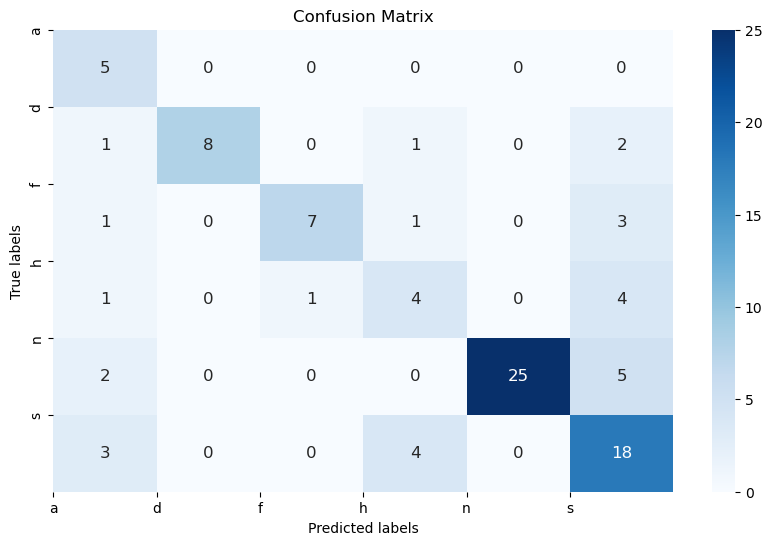

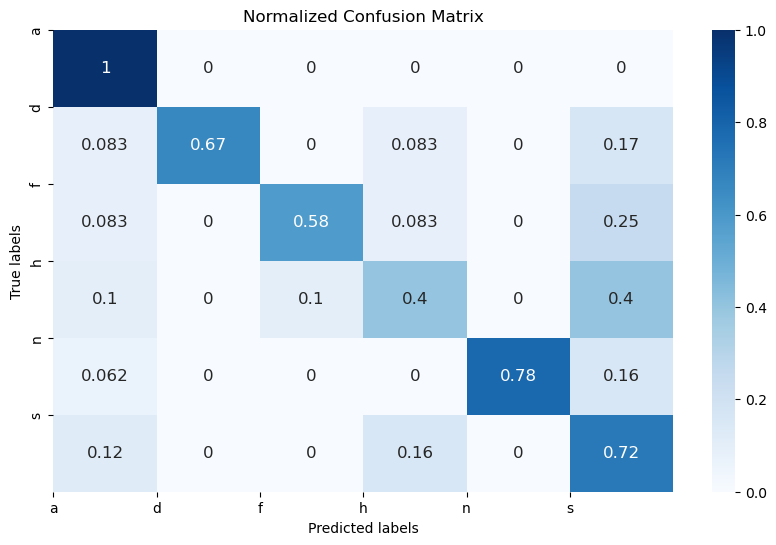

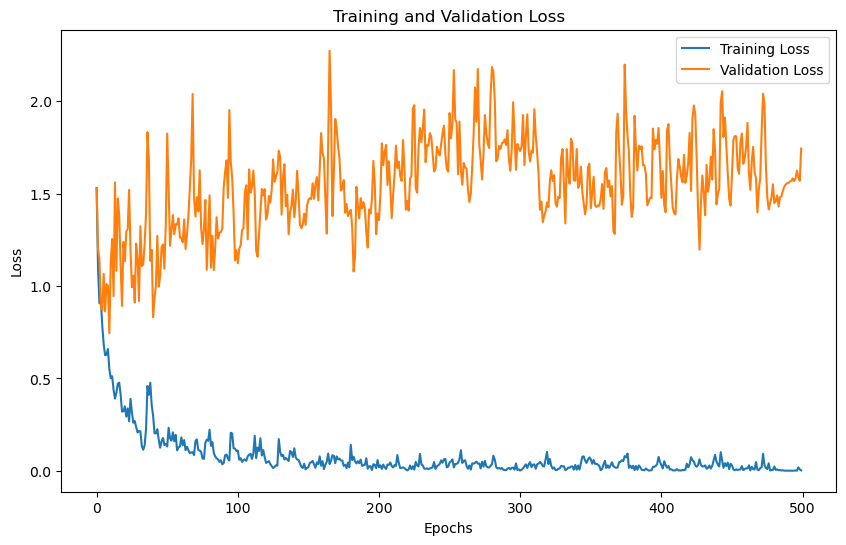

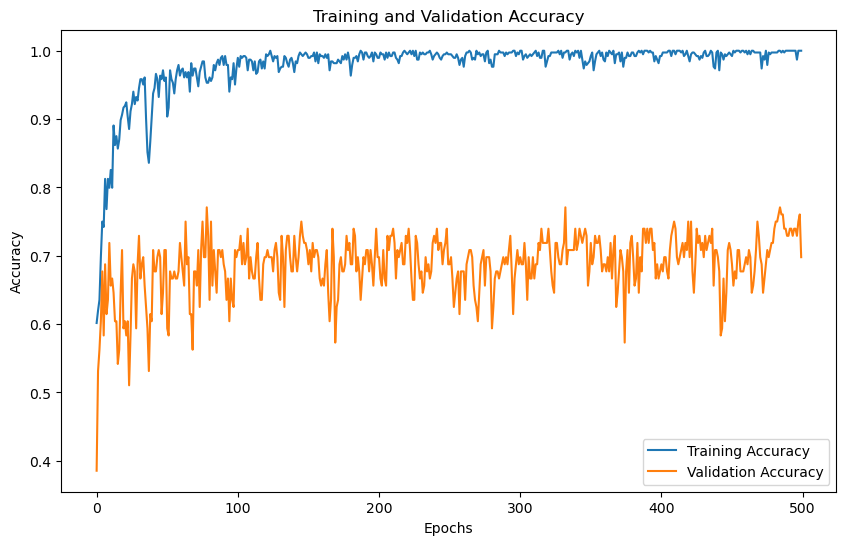

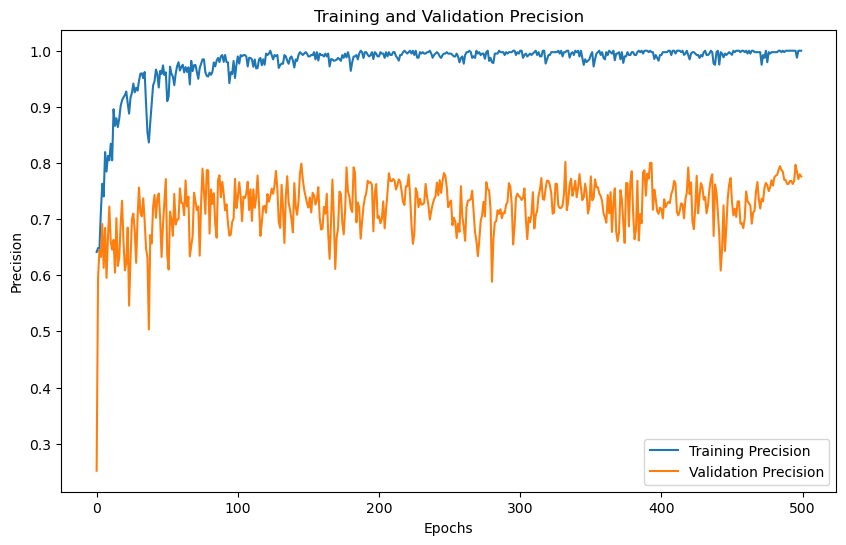

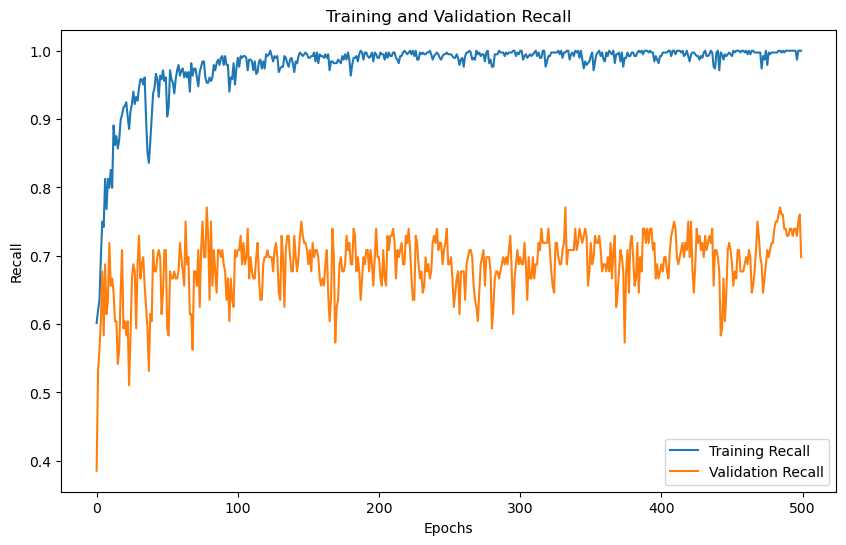

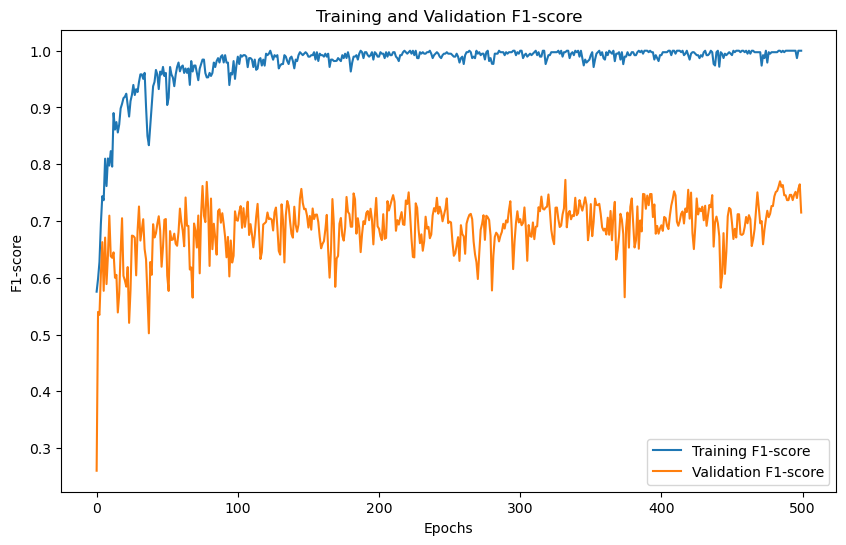

'Model Training and Evaluation Successfully completed'

In [33]:
train_model()

# SAVEE
# DWT 1
# N_MFCC 24
# 500 epoch

In [ ]:
train_model()

# SAVEE
# DWT 5
# N_MFCC 24
# 500 epoch

In [ ]:
train_model()

Enter dataset name:
tess, savee, crema, ravdess
 savee
Enter dwt level:  5
Enter Number of MFCC coefficients : 24
No. of classes 6
Input size for wavelet level 5 = 144
Training with DWT level: 5
Hidden Size : 256
Model Name: Resnet18_RNN_Model

X Shape : (480, 1, 144)
Y Shape : (480, 6)



# RAVDESS
# DWT 1
# N_MFCC 24

Enter dataset name:
tess, savee, crema, ravdess
 ravdess
Enter dwt level:  1
Enter Number of MFCC coefficients : 24
No. of classes 8
Input size for wavelet level 1 = 48
Training with DWT level: 1
Hidden Size : 256
Model Name: Resnet18_RNN_Model

X Shape : (1440, 1, 48)
Y Shape : (1440, 8)

Enter no. of epochs 500
Epoch [1/500],
Training Loss: 1.8948, Training Accuracy: 0.3464, Training Precision:0.3551,Training Recall:0.3464,Training F1-Score:0.2996
Validation Loss: 1.7018, Validation Accuracy: 0.3819, Validation Precision:0.3520,Validation Recall:0.3819,Validation F1-Score:0.3247
Epoch [2/500],
Training Loss: 1.7311, Training Accuracy: 0.3724, Training Precision:0.3546,Training Recall:0.3724,Training F1-Score:0.3266
Validation Loss: 1.6784, Validation Accuracy: 0.3611, Validation Precision:0.3313,Validation Recall:0.3611,Validation F1-Score:0.3166
Epoch [3/500],
Training Loss: 1.6722, Training Accuracy: 0.3863, Training Precision:0.3679,Training Recall:0.3863,Training F1-Score:0.3338


Epoch [30/500],
Training Loss: 1.1287, Training Accuracy: 0.5825, Training Precision:0.5877,Training Recall:0.5825,Training F1-Score:0.5796
Validation Loss: 1.3754, Validation Accuracy: 0.5069, Validation Precision:0.5178,Validation Recall:0.5069,Validation F1-Score:0.5060
Epoch [31/500],
Training Loss: 1.0950, Training Accuracy: 0.6007, Training Precision:0.6042,Training Recall:0.6007,Training F1-Score:0.6001
Validation Loss: 1.3423, Validation Accuracy: 0.5069, Validation Precision:0.5302,Validation Recall:0.5069,Validation F1-Score:0.5077
Epoch [32/500],
Training Loss: 1.1279, Training Accuracy: 0.6285, Training Precision:0.6355,Training Recall:0.6285,Training F1-Score:0.6287
Validation Loss: 1.6333, Validation Accuracy: 0.3924, Validation Precision:0.4145,Validation Recall:0.3924,Validation F1-Score:0.3852
Epoch [33/500],
Training Loss: 1.0477, Training Accuracy: 0.6207, Training Precision:0.6359,Training Recall:0.6207,Training F1-Score:0.6202
Validation Loss: 1.4929, Validation Ac

Epoch [60/500],
Training Loss: 0.6472, Training Accuracy: 0.7899, Training Precision:0.7952,Training Recall:0.7899,Training F1-Score:0.7910
Validation Loss: 1.2806, Validation Accuracy: 0.5382, Validation Precision:0.5606,Validation Recall:0.5382,Validation F1-Score:0.5431
Epoch [61/500],
Training Loss: 0.6168, Training Accuracy: 0.8160, Training Precision:0.8194,Training Recall:0.8160,Training F1-Score:0.8166
Validation Loss: 1.2641, Validation Accuracy: 0.5660, Validation Precision:0.5748,Validation Recall:0.5660,Validation F1-Score:0.5659
Epoch [62/500],
Training Loss: 0.6948, Training Accuracy: 0.7856, Training Precision:0.7934,Training Recall:0.7856,Training F1-Score:0.7861
Validation Loss: 1.2771, Validation Accuracy: 0.5347, Validation Precision:0.5541,Validation Recall:0.5347,Validation F1-Score:0.5386
Epoch [63/500],
Training Loss: 0.6290, Training Accuracy: 0.7847, Training Precision:0.7886,Training Recall:0.7847,Training F1-Score:0.7855
Validation Loss: 1.3310, Validation Ac

Epoch [90/500],
Training Loss: 0.3489, Training Accuracy: 0.8880, Training Precision:0.8883,Training Recall:0.8880,Training F1-Score:0.8879
Validation Loss: 1.5473, Validation Accuracy: 0.5660, Validation Precision:0.5772,Validation Recall:0.5660,Validation F1-Score:0.5591
Epoch [91/500],
Training Loss: 0.3419, Training Accuracy: 0.9115, Training Precision:0.9129,Training Recall:0.9115,Training F1-Score:0.9111
Validation Loss: 1.4346, Validation Accuracy: 0.6076, Validation Precision:0.6131,Validation Recall:0.6076,Validation F1-Score:0.6002
Epoch [92/500],
Training Loss: 0.3114, Training Accuracy: 0.9054, Training Precision:0.9059,Training Recall:0.9054,Training F1-Score:0.9054
Validation Loss: 1.2977, Validation Accuracy: 0.5625, Validation Precision:0.5592,Validation Recall:0.5625,Validation F1-Score:0.5575
Epoch [93/500],
Training Loss: 0.2748, Training Accuracy: 0.9227, Training Precision:0.9232,Training Recall:0.9227,Training F1-Score:0.9226
Validation Loss: 1.5494, Validation Ac

Epoch [120/500],
Training Loss: 0.1499, Training Accuracy: 0.9679, Training Precision:0.9684,Training Recall:0.9679,Training F1-Score:0.9680
Validation Loss: 1.5160, Validation Accuracy: 0.6319, Validation Precision:0.6258,Validation Recall:0.6319,Validation F1-Score:0.6260
Epoch [121/500],
Training Loss: 0.1542, Training Accuracy: 0.9488, Training Precision:0.9492,Training Recall:0.9488,Training F1-Score:0.9488
Validation Loss: 1.7345, Validation Accuracy: 0.6076, Validation Precision:0.6174,Validation Recall:0.6076,Validation F1-Score:0.6025
Epoch [122/500],
Training Loss: 0.1543, Training Accuracy: 0.9688, Training Precision:0.9693,Training Recall:0.9688,Training F1-Score:0.9688
Validation Loss: 1.6317, Validation Accuracy: 0.6111, Validation Precision:0.6135,Validation Recall:0.6111,Validation F1-Score:0.6102
Epoch [123/500],
Training Loss: 0.1835, Training Accuracy: 0.9418, Training Precision:0.9437,Training Recall:0.9418,Training F1-Score:0.9423
Validation Loss: 1.6110, Validatio

...

Epoch [360/500],
Training Loss: 0.0711, Training Accuracy: 0.9722, Training Precision:0.9730,Training Recall:0.9722,Training F1-Score:0.9723
Validation Loss: 1.9202, Validation Accuracy: 0.6042, Validation Precision:0.6147,Validation Recall:0.6042,Validation F1-Score:0.6068
Epoch [361/500],
Training Loss: 0.0648, Training Accuracy: 0.9922, Training Precision:0.9923,Training Recall:0.9922,Training F1-Score:0.9922
Validation Loss: 1.8087, Validation Accuracy: 0.6528, Validation Precision:0.6650,Validation Recall:0.6528,Validation F1-Score:0.6511
Epoch [362/500],
Training Loss: 0.0186, Training Accuracy: 0.9905, Training Precision:0.9905,Training Recall:0.9905,Training F1-Score:0.9904
Validation Loss: 1.8865, Validation Accuracy: 0.6389, Validation Precision:0.6396,Validation Recall:0.6389,Validation F1-Score:0.6354
Epoch [363/500],
Training Loss: 0.0366, Training Accuracy: 0.9878, Training Precision:0.9880,Training Recall:0.9878,Training F1-Score:0.9878
Validation Loss: 1.5657, Validatio

Epoch [390/500],
Training Loss: 0.0318, Training Accuracy: 0.9931, Training Precision:0.9935,Training Recall:0.9931,Training F1-Score:0.9931
Validation Loss: 1.7484, Validation Accuracy: 0.7014, Validation Precision:0.7073,Validation Recall:0.7014,Validation F1-Score:0.6990
Epoch [391/500],
Training Loss: 0.0381, Training Accuracy: 0.9931, Training Precision:0.9931,Training Recall:0.9931,Training F1-Score:0.9931
Validation Loss: 1.7710, Validation Accuracy: 0.6840, Validation Precision:0.6911,Validation Recall:0.6840,Validation F1-Score:0.6841
Epoch [392/500],
Training Loss: 0.0436, Training Accuracy: 0.9878, Training Precision:0.9881,Training Recall:0.9878,Training F1-Score:0.9879
Validation Loss: 1.8838, Validation Accuracy: 0.6771, Validation Precision:0.6947,Validation Recall:0.6771,Validation F1-Score:0.6755
Epoch [393/500],
Training Loss: 0.0363, Training Accuracy: 0.9861, Training Precision:0.9864,Training Recall:0.9861,Training F1-Score:0.9862
Validation Loss: 1.7749, Validatio

Epoch [420/500],
Training Loss: 0.0623, Training Accuracy: 0.9922, Training Precision:0.9923,Training Recall:0.9922,Training F1-Score:0.9922
Validation Loss: 2.0310, Validation Accuracy: 0.6285, Validation Precision:0.6242,Validation Recall:0.6285,Validation F1-Score:0.6217
Epoch [421/500],
Training Loss: 0.0621, Training Accuracy: 0.9844, Training Precision:0.9845,Training Recall:0.9844,Training F1-Score:0.9844
Validation Loss: 2.0185, Validation Accuracy: 0.6285, Validation Precision:0.6296,Validation Recall:0.6285,Validation F1-Score:0.6288
Epoch [422/500],
Training Loss: 0.0864, Training Accuracy: 0.9870, Training Precision:0.9873,Training Recall:0.9870,Training F1-Score:0.9870
Validation Loss: 1.7737, Validation Accuracy: 0.6667, Validation Precision:0.6685,Validation Recall:0.6667,Validation F1-Score:0.6624
Epoch [423/500],
Training Loss: 0.0520, Training Accuracy: 0.9931, Training Precision:0.9932,Training Recall:0.9931,Training F1-Score:0.9931
Validation Loss: 1.8470, Validatio

Epoch [450/500],
Training Loss: 0.0602, Training Accuracy: 0.9861, Training Precision:0.9862,Training Recall:0.9861,Training F1-Score:0.9861
Validation Loss: 1.9702, Validation Accuracy: 0.6354, Validation Precision:0.6493,Validation Recall:0.6354,Validation F1-Score:0.6316
Epoch [451/500],
Training Loss: 0.0524, Training Accuracy: 0.9896, Training Precision:0.9897,Training Recall:0.9896,Training F1-Score:0.9896
Validation Loss: 1.8937, Validation Accuracy: 0.6562, Validation Precision:0.6539,Validation Recall:0.6562,Validation F1-Score:0.6527
Epoch [452/500],
Training Loss: 0.0604, Training Accuracy: 0.9861, Training Precision:0.9863,Training Recall:0.9861,Training F1-Score:0.9861
Validation Loss: 2.0582, Validation Accuracy: 0.6181, Validation Precision:0.6230,Validation Recall:0.6181,Validation F1-Score:0.6164
Epoch [453/500],
Training Loss: 0.0291, Training Accuracy: 0.9905, Training Precision:0.9905,Training Recall:0.9905,Training F1-Score:0.9904
Validation Loss: 1.7996, Validatio

Epoch [480/500],
Training Loss: 0.0313, Training Accuracy: 0.9948, Training Precision:0.9948,Training Recall:0.9948,Training F1-Score:0.9948
Validation Loss: 1.7223, Validation Accuracy: 0.6910, Validation Precision:0.7005,Validation Recall:0.6910,Validation F1-Score:0.6907
Epoch [481/500],
Training Loss: 0.0176, Training Accuracy: 0.9948, Training Precision:0.9948,Training Recall:0.9948,Training F1-Score:0.9948
Validation Loss: 1.9789, Validation Accuracy: 0.6528, Validation Precision:0.6663,Validation Recall:0.6528,Validation F1-Score:0.6503
Epoch [482/500],
Training Loss: 0.0119, Training Accuracy: 0.9957, Training Precision:0.9957,Training Recall:0.9957,Training F1-Score:0.9957
Validation Loss: 1.9070, Validation Accuracy: 0.6632, Validation Precision:0.6706,Validation Recall:0.6632,Validation F1-Score:0.6632
Epoch [483/500],
Training Loss: 0.0221, Training Accuracy: 0.9974, Training Precision:0.9974,Training Recall:0.9974,Training F1-Score:0.9974
Validation Loss: 1.9664, Validatio

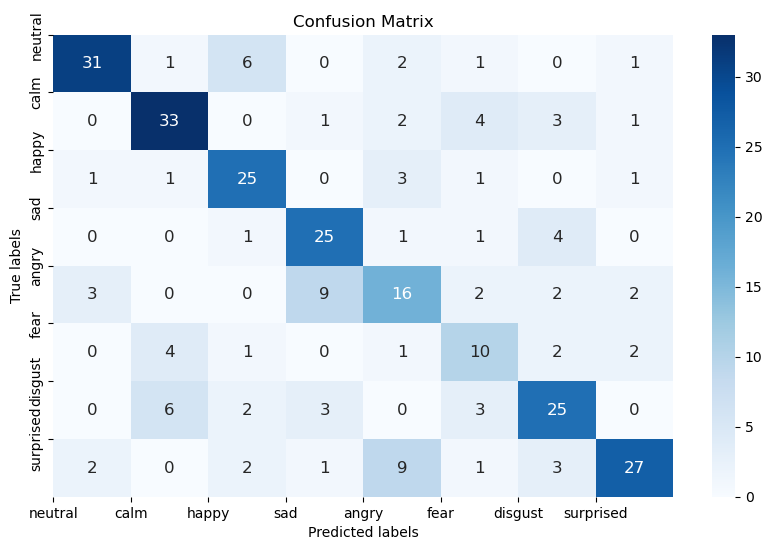

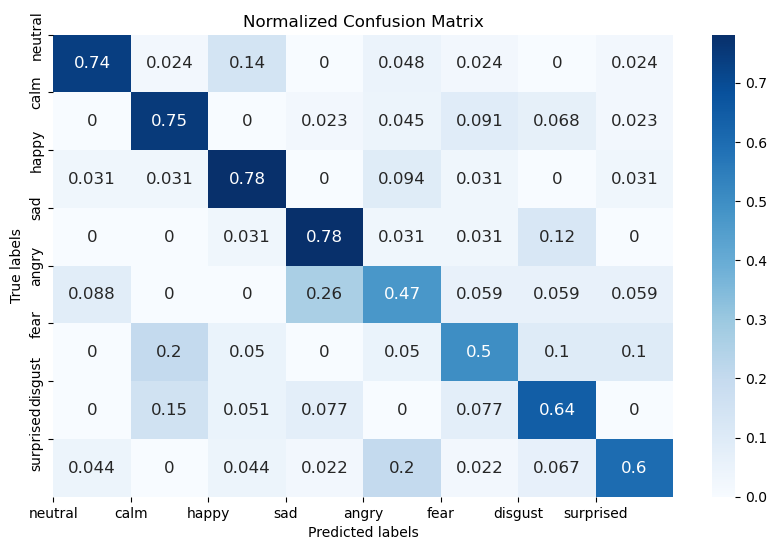

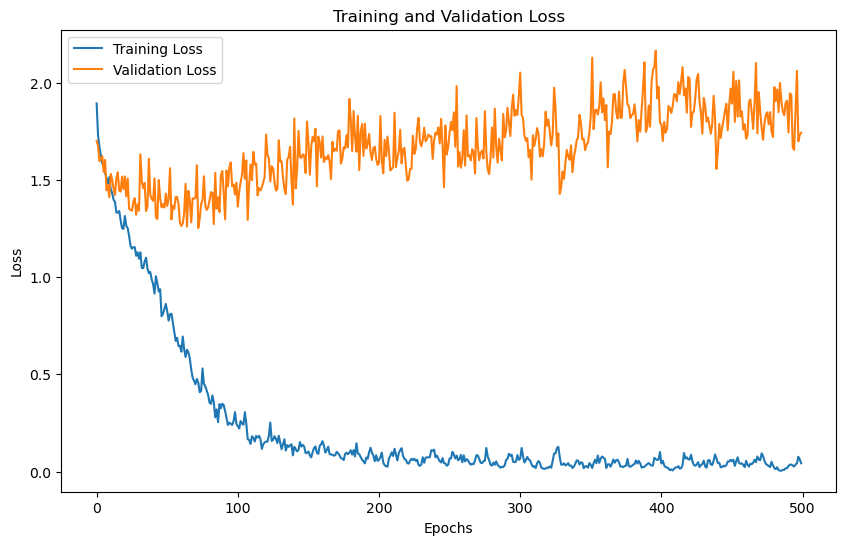

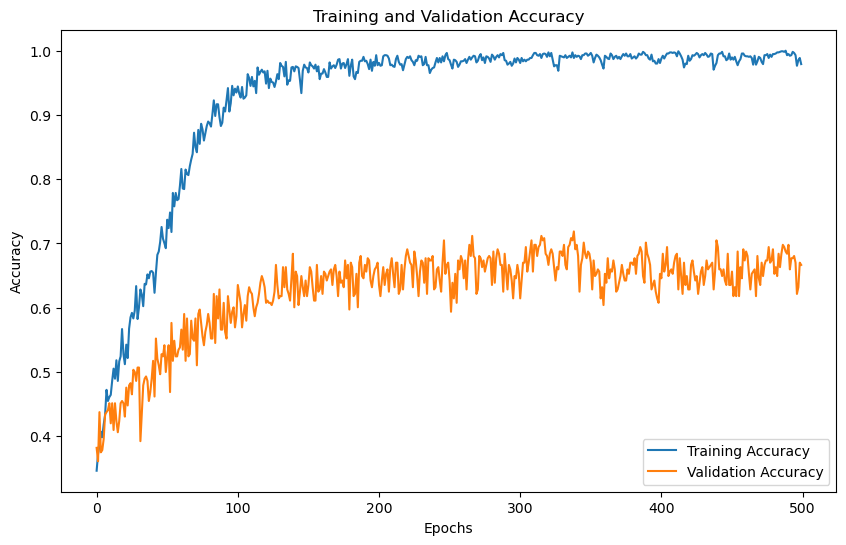

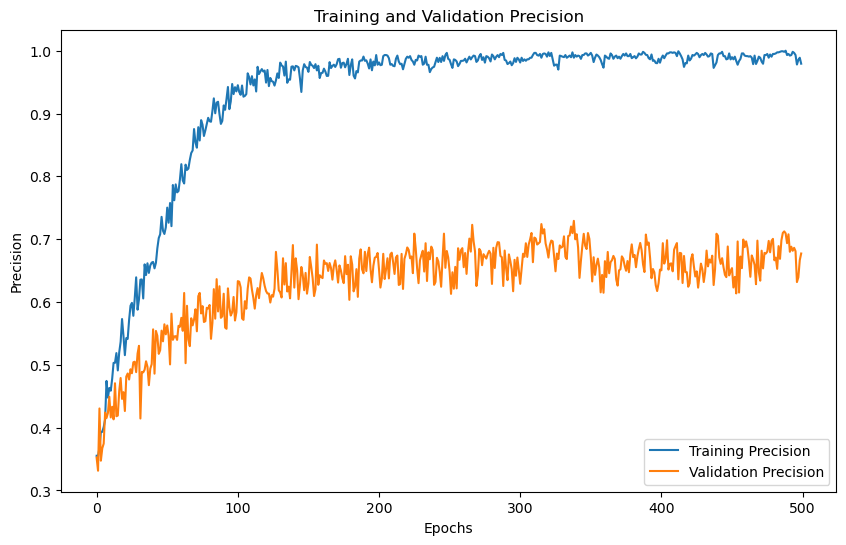

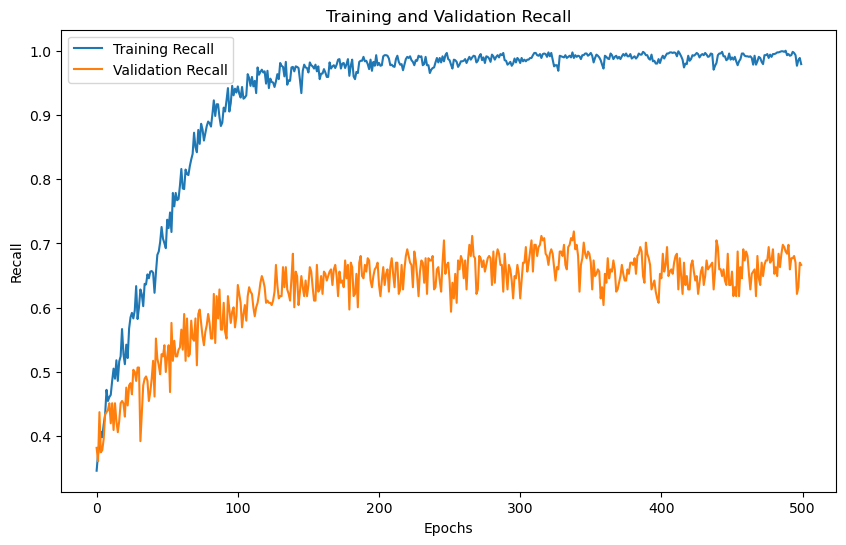

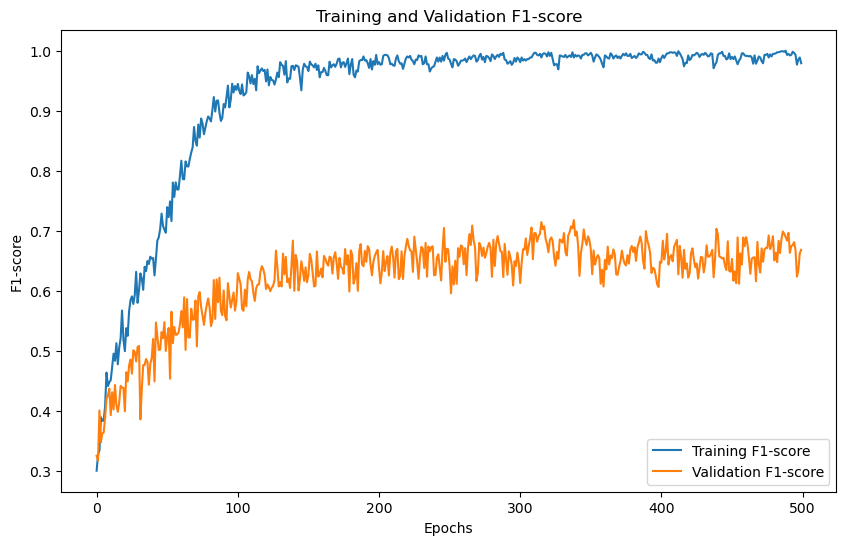

'Model Training and Evaluation Successfully completed'

In [40]:
train_model()

# RAVDESS
# DWT 2
# N_MFCC 24

In [ ]:
train_model()

# TESS
# DWT 1
# N_MFCC 32

Enter dataset name:
tess, savee, crema, ravdess
 tess
Enter dwt level:  1
Enter Number of MFCC coefficients : 32
No. of classes 7
Input size for wavelet level 1 = 64
Training with DWT level: 1
Hidden Size : 256
Model Name: Resnet18_RNN_Model

X Shape : (2800, 1, 64)
Y Shape : (2800, 7)

Enter no. of epochs 500
Epoch [1/500],
Training Loss: 0.5394, Training Accuracy: 0.9254, Training Precision:0.9297,Training Recall:0.9254,Training F1-Score:0.9249
Validation Loss: 0.2543, Validation Accuracy: 0.9214, Validation Precision:0.9232,Validation Recall:0.9214,Validation F1-Score:0.9199
Epoch [2/500],
Training Loss: 0.2443, Training Accuracy: 0.9237, Training Precision:0.9245,Training Recall:0.9237,Training F1-Score:0.9235
Validation Loss: 0.2578, Validation Accuracy: 0.9232, Validation Precision:0.9249,Validation Recall:0.9232,Validation F1-Score:0.9226
Epoch [3/500],
Training Loss: 0.1951, Training Accuracy: 0.9317, Training Precision:0.9377,Training Recall:0.9317,Training F1-Score:0.9329
Val

Epoch [30/500],
Training Loss: 0.0266, Training Accuracy: 0.9906, Training Precision:0.9909,Training Recall:0.9906,Training F1-Score:0.9906
Validation Loss: 0.0911, Validation Accuracy: 0.9804, Validation Precision:0.9810,Validation Recall:0.9804,Validation F1-Score:0.9804
Epoch [31/500],
Training Loss: 0.0380, Training Accuracy: 0.9946, Training Precision:0.9947,Training Recall:0.9946,Training F1-Score:0.9946
Validation Loss: 0.0424, Validation Accuracy: 0.9875, Validation Precision:0.9878,Validation Recall:0.9875,Validation F1-Score:0.9875
Epoch [32/500],
Training Loss: 0.0245, Training Accuracy: 0.9924, Training Precision:0.9925,Training Recall:0.9924,Training F1-Score:0.9924
Validation Loss: 0.0515, Validation Accuracy: 0.9875, Validation Precision:0.9879,Validation Recall:0.9875,Validation F1-Score:0.9875
Epoch [33/500],
Training Loss: 0.0324, Training Accuracy: 0.9942, Training Precision:0.9942,Training Recall:0.9942,Training F1-Score:0.9942
Validation Loss: 0.0445, Validation Ac

Epoch [60/500],
Training Loss: 0.0119, Training Accuracy: 0.9982, Training Precision:0.9982,Training Recall:0.9982,Training F1-Score:0.9982
Validation Loss: 0.0232, Validation Accuracy: 0.9929, Validation Precision:0.9929,Validation Recall:0.9929,Validation F1-Score:0.9929
Epoch [61/500],
Training Loss: 0.0121, Training Accuracy: 0.9987, Training Precision:0.9987,Training Recall:0.9987,Training F1-Score:0.9987
Validation Loss: 0.0334, Validation Accuracy: 0.9857, Validation Precision:0.9863,Validation Recall:0.9857,Validation F1-Score:0.9857
Epoch [62/500],
Training Loss: 0.0114, Training Accuracy: 0.9964, Training Precision:0.9965,Training Recall:0.9964,Training F1-Score:0.9964
Validation Loss: 0.0325, Validation Accuracy: 0.9893, Validation Precision:0.9897,Validation Recall:0.9893,Validation F1-Score:0.9893
Epoch [63/500],
Training Loss: 0.0224, Training Accuracy: 0.9929, Training Precision:0.9930,Training Recall:0.9929,Training F1-Score:0.9928
Validation Loss: 0.0520, Validation Ac

Epoch [90/500],
Training Loss: 0.0088, Training Accuracy: 0.9991, Training Precision:0.9991,Training Recall:0.9991,Training F1-Score:0.9991
Validation Loss: 0.0219, Validation Accuracy: 0.9946, Validation Precision:0.9947,Validation Recall:0.9946,Validation F1-Score:0.9946
Epoch [91/500],
Training Loss: 0.0031, Training Accuracy: 0.9978, Training Precision:0.9978,Training Recall:0.9978,Training F1-Score:0.9978
Validation Loss: 0.0464, Validation Accuracy: 0.9893, Validation Precision:0.9897,Validation Recall:0.9893,Validation F1-Score:0.9894
Epoch [92/500],
Training Loss: 0.0125, Training Accuracy: 0.9929, Training Precision:0.9930,Training Recall:0.9929,Training F1-Score:0.9929
Validation Loss: 0.0378, Validation Accuracy: 0.9893, Validation Precision:0.9896,Validation Recall:0.9893,Validation F1-Score:0.9893
Epoch [93/500],
Training Loss: 0.0172, Training Accuracy: 0.9964, Training Precision:0.9965,Training Recall:0.9964,Training F1-Score:0.9964
Validation Loss: 0.0649, Validation Ac

Epoch [120/500],
Training Loss: 0.0484, Training Accuracy: 0.9857, Training Precision:0.9862,Training Recall:0.9857,Training F1-Score:0.9857
Validation Loss: 0.0759, Validation Accuracy: 0.9768, Validation Precision:0.9778,Validation Recall:0.9768,Validation F1-Score:0.9769
Epoch [121/500],
Training Loss: 0.0136, Training Accuracy: 0.9964, Training Precision:0.9965,Training Recall:0.9964,Training F1-Score:0.9964
Validation Loss: 0.0502, Validation Accuracy: 0.9929, Validation Precision:0.9929,Validation Recall:0.9929,Validation F1-Score:0.9929
Epoch [122/500],
Training Loss: 0.0141, Training Accuracy: 0.9991, Training Precision:0.9991,Training Recall:0.9991,Training F1-Score:0.9991
Validation Loss: 0.0495, Validation Accuracy: 0.9857, Validation Precision:0.9861,Validation Recall:0.9857,Validation F1-Score:0.9857
Epoch [123/500],
Training Loss: 0.0194, Training Accuracy: 0.9862, Training Precision:0.9869,Training Recall:0.9862,Training F1-Score:0.9861
Validation Loss: 0.0478, Validatio

...

Epoch [360/500],
Training Loss: 0.0001, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 0.0229, Validation Accuracy: 0.9964, Validation Precision:0.9965,Validation Recall:0.9964,Validation F1-Score:0.9964
Epoch [361/500],
Training Loss: 0.0001, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 0.0267, Validation Accuracy: 0.9946, Validation Precision:0.9948,Validation Recall:0.9946,Validation F1-Score:0.9947
Epoch [362/500],
Training Loss: 0.0001, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 0.0341, Validation Accuracy: 0.9946, Validation Precision:0.9948,Validation Recall:0.9946,Validation F1-Score:0.9947
Epoch [363/500],
Training Loss: 0.0002, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 0.0293, Validatio

Epoch [390/500],
Training Loss: 0.0000, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 0.0411, Validation Accuracy: 0.9946, Validation Precision:0.9948,Validation Recall:0.9946,Validation F1-Score:0.9947
Epoch [391/500],
Training Loss: 0.0000, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 0.0308, Validation Accuracy: 0.9946, Validation Precision:0.9947,Validation Recall:0.9946,Validation F1-Score:0.9946
Epoch [392/500],
Training Loss: 0.0001, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 0.0389, Validation Accuracy: 0.9946, Validation Precision:0.9948,Validation Recall:0.9946,Validation F1-Score:0.9947
Epoch [393/500],
Training Loss: 0.0000, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 0.0342, Validatio

Epoch [420/500],
Training Loss: 0.0000, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 0.0253, Validation Accuracy: 0.9946, Validation Precision:0.9947,Validation Recall:0.9946,Validation F1-Score:0.9947
Epoch [421/500],
Training Loss: 0.0000, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 0.0250, Validation Accuracy: 0.9964, Validation Precision:0.9965,Validation Recall:0.9964,Validation F1-Score:0.9964
Epoch [422/500],
Training Loss: 0.0000, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 0.0235, Validation Accuracy: 0.9964, Validation Precision:0.9965,Validation Recall:0.9964,Validation F1-Score:0.9964
Epoch [423/500],
Training Loss: 0.0000, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 0.0219, Validatio

Epoch [450/500],
Training Loss: 0.0000, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 0.0315, Validation Accuracy: 0.9964, Validation Precision:0.9965,Validation Recall:0.9964,Validation F1-Score:0.9964
Epoch [451/500],
Training Loss: 0.0000, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 0.0324, Validation Accuracy: 0.9964, Validation Precision:0.9965,Validation Recall:0.9964,Validation F1-Score:0.9964
Epoch [452/500],
Training Loss: 0.0000, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 0.0390, Validation Accuracy: 0.9946, Validation Precision:0.9948,Validation Recall:0.9946,Validation F1-Score:0.9947
Epoch [453/500],
Training Loss: 0.0000, Training Accuracy: 1.0000, Training Precision:1.0000,Training Recall:1.0000,Training F1-Score:1.0000
Validation Loss: 0.0317, Validatio

Epoch [480/500],
Training Loss: 0.0203, Training Accuracy: 0.9946, Training Precision:0.9948,Training Recall:0.9946,Training F1-Score:0.9946
Validation Loss: 0.0421, Validation Accuracy: 0.9929, Validation Precision:0.9929,Validation Recall:0.9929,Validation F1-Score:0.9928
Epoch [481/500],
Training Loss: 0.0092, Training Accuracy: 0.9942, Training Precision:0.9944,Training Recall:0.9942,Training F1-Score:0.9942
Validation Loss: 0.0522, Validation Accuracy: 0.9839, Validation Precision:0.9848,Validation Recall:0.9839,Validation F1-Score:0.9839
Epoch [482/500],
Training Loss: 0.0113, Training Accuracy: 0.9969, Training Precision:0.9969,Training Recall:0.9969,Training F1-Score:0.9969
Validation Loss: 0.0414, Validation Accuracy: 0.9893, Validation Precision:0.9895,Validation Recall:0.9893,Validation F1-Score:0.9893
Epoch [483/500],
Training Loss: 0.0090, Training Accuracy: 0.9991, Training Precision:0.9991,Training Recall:0.9991,Training F1-Score:0.9991
Validation Loss: 0.0213, Validatio

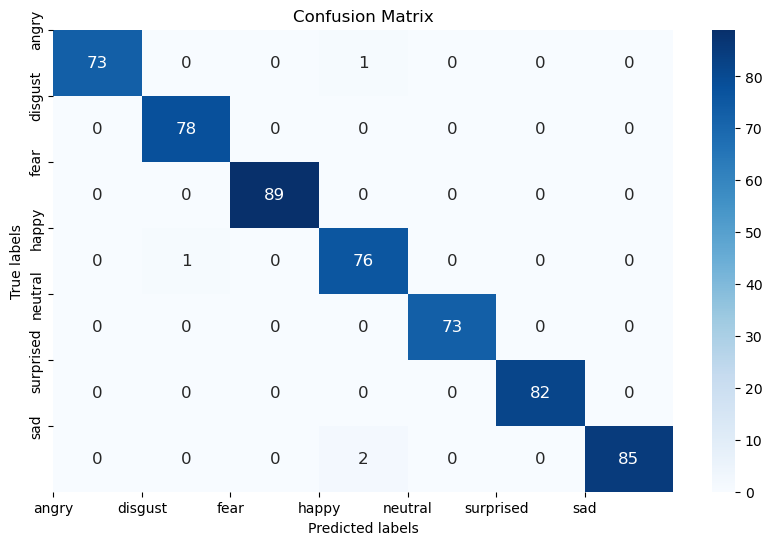

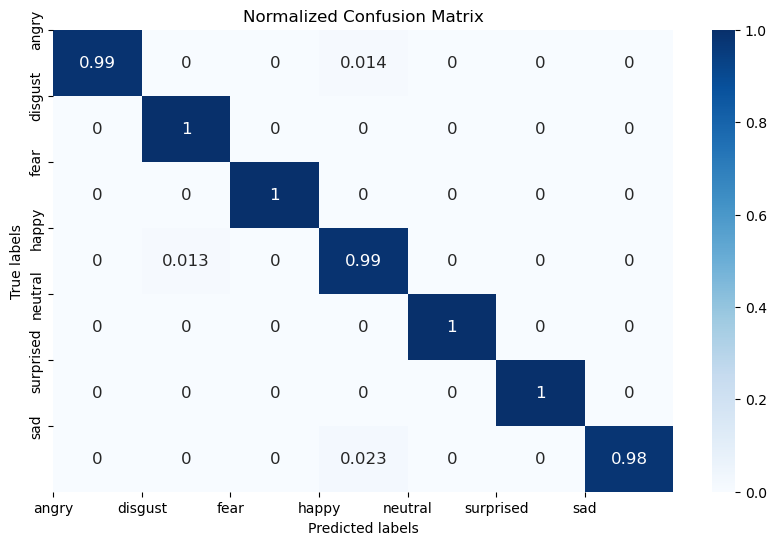

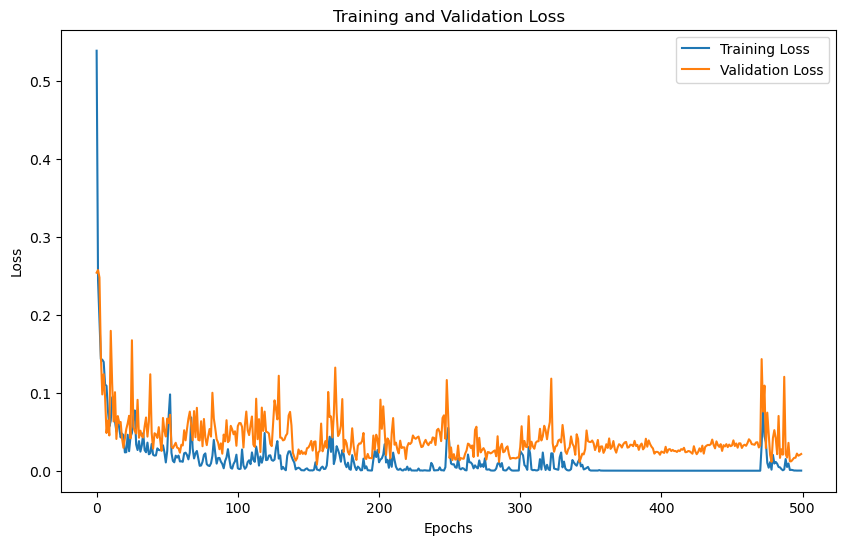

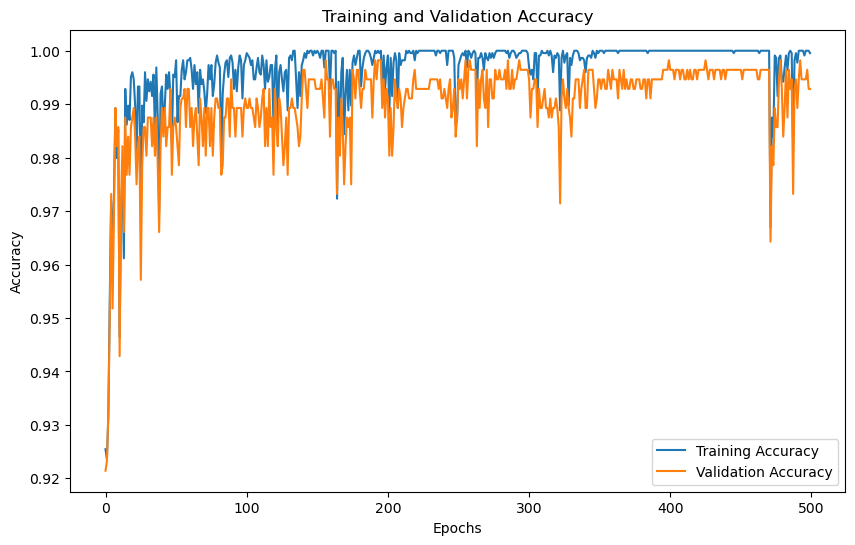

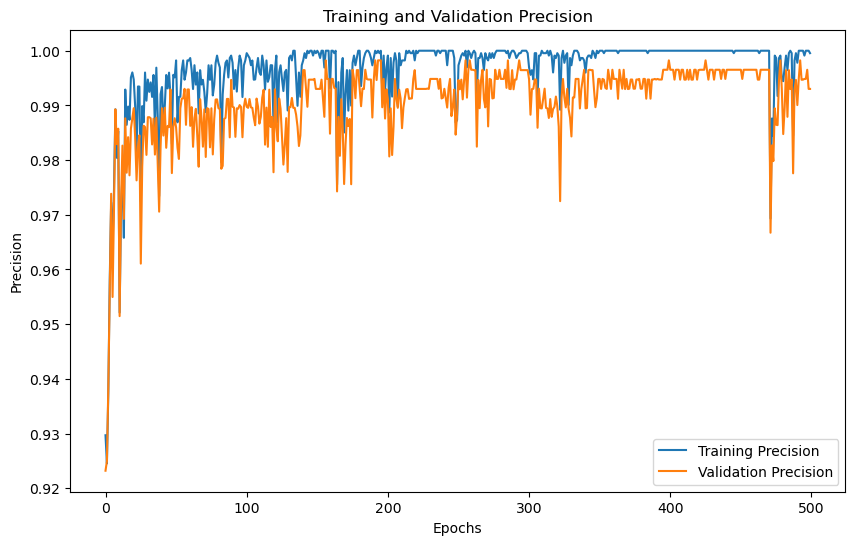

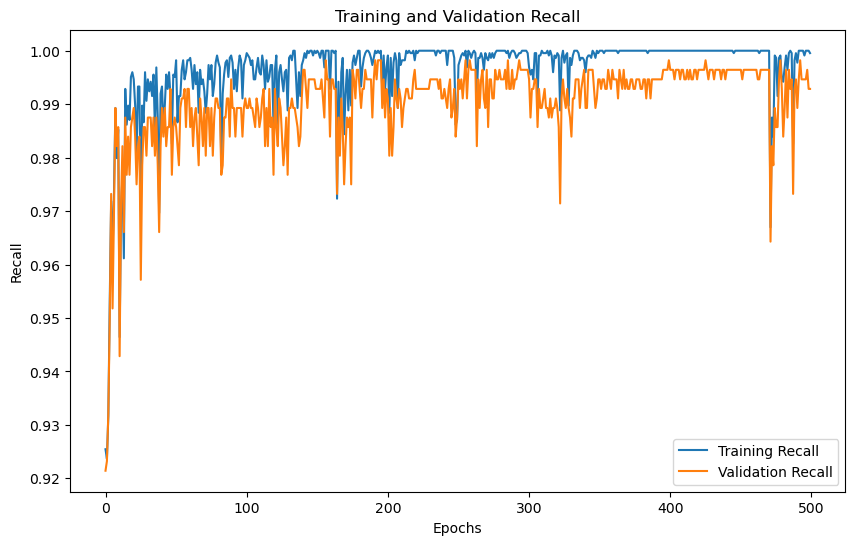

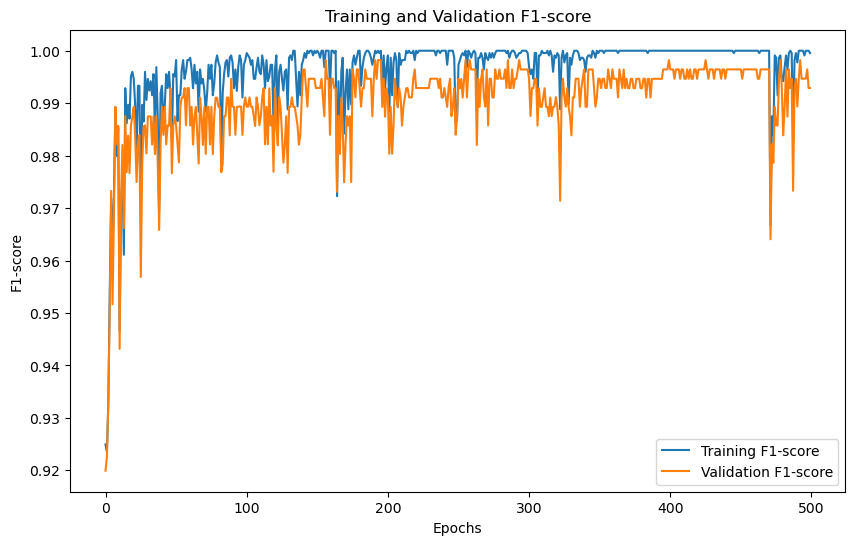

'Model Training and Evaluation Successfully completed'

In [41]:
train_model()

# TESS
# DWT 3
# N_MFCC 32

In [ ]:
train_model()

# TESS
# DWT 3
# N_MFCC 32

In [ ]:
train_model()

# TESS
# DWT 5
# N_MFCC 32

In [ ]:
train_model()

# TESS
# DWT 1
# N_MFCC 40

In [ ]:
train_model()

In [ ]:
train_model()

# CREMA
# DWT 1
# N_MFCC 16

In [13]:
train_model()

Enter dataset name:
tess, savee, crema, ravdess
 crema
Enter dwt level:  1
Enter Number of MFCC coefficients : 40
No. of classes 6
Input size for wavelet level 1 = 80
Training with DWT level: 1
Hidden Size : 256
Model Name: Resnet18_RNN_Model

X Shape : (7442, 1, 80)
Y Shape : (7442, 6)

Enter no. of epochs 200


RuntimeError: mat1 and mat2 shapes cannot be multiplied (64x256 and 128x6)